# TFM Equipo Ethos · Entrega 3 · Analítica avanzada y datos para Power BI

**Máster en Business Analytics e IA · INESDI**

Este notebook cubre la parte **opcional** de la Entrega 3 (analítica avanzada y Machine Learning) y además **genera el modelo de datos que alimenta el informe de Power BI**, de modo que todo el flujo es reproducible:

```
datasabadell_actualizado_con_segmentos.xlsx  (salida de la Entrega 2)
        │
        ▼
Este notebook: preparación · correlaciones · segmentación K-Means · modelo de propensión
        │
        ▼
PowerBI/TFM_Ethos_datos.xlsx  (modelo en estrella: 12 hojas)  ──►  TFM_Ethos_Cartera.pbip
```

| Sección | Técnica | Pregunta de negocio |
|---|---|---|
| 1 | Preparación de variables | Variables limpias y con categorías legibles para el informe |
| 2 | Correlación de Spearman | ¿Qué variables se mueven juntas? |
| 3 | AUC univariante, chi-cuadrado y V de Cramér | ¿Qué rasgos distinguen a los clientes que invierten? |
| 4 | LocalOutlierFactor + K-Means + PCA | ¿Qué grupos de clientes existen según su comportamiento? |
| 5 | Regresión logística, KNN, SVM y Random Forest | ¿Qué clientes sin inversión tienen más probabilidad de invertir? |
| 6 | Exportación del modelo en estrella | Tablas listas para Power BI |

Semillas fijadas (`RANDOM_STATE = 42`): los resultados son reproducibles.

In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor, KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, recall_score, precision_score, f1_score,
                             accuracy_score, confusion_matrix, silhouette_score)

RANDOM_STATE = 42
ENTRADA = Path('datasabadell_actualizado_con_segmentos.xlsx')          # salida de la Entrega 2
SALIDA = Path('..') / 'PowerBI' / 'TFM_Ethos_datos.xlsx'               # origen de datos del Power BI

# Paleta (la misma que usa el tema del informe de Power BI)
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#4a3aa7']
AZUL_OSCURO, GRIS, TINTA, TINTA_2, REJILLA = '#0f2a4a', '#c3c2b7', '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({
    'axes.edgecolor': GRIS, 'axes.labelcolor': TINTA_2, 'axes.titlecolor': TINTA, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'figure.dpi': 100,
})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)

df = pd.read_excel(ENTRADA)
print(f"Dataset cargado: {df.shape[0]:,} clientes x {df.shape[1]} columnas".replace(',', '.'))

Dataset cargado: 9.822 clientes x 96 columnas


## 1. Preparación de variables
Se parte del dataset limpio de la Entrega 2 y se crean las variables que necesitan el análisis y el informe de Power BI:

- **Importes:**
  - `gastos_tot` pasa de texto moneda a número; las dos celdas con `##########` quedan como nulo.
  - `deuda_total = crédito + revolving + hipoteca`.
  - `ratio_endeudamiento = deuda / patrimonio` y su nivel de riesgo.
- **Rangos legibles con su columna de orden**, para que Power BI los ordene bien: rango de edad, tramo de patrimonio, tramo de nº de productos, nivel de renta y grupo de antigüedad.
- **Indicadores Sí/No:** tiene inversión, mono-producto, tiene nómina, renta imputada, residente.

In [2]:
def convertir_moneda(serie):
    limpio = (serie.astype(str).str.replace('€', '', regex=False).str.replace(',', '', regex=False).str.strip())
    limpio = limpio.replace({'-': '0', '': np.nan, 'nan': np.nan})
    limpio = limpio.mask(limpio.str.fullmatch(r'#+', na=False))
    return pd.to_numeric(limpio, errors='coerce')

si_no = lambda s: np.where(s.astype(bool), 'Sí', 'No')
d = df.copy()
d['gastos'] = convertir_moneda(d['gastos_tot']) if not pd.api.types.is_numeric_dtype(d['gastos_tot']) else d['gastos_tot']
d['deuda_total'] = d[['credit', 'revolving', 'tothipo']].fillna(0).sum(axis=1)
d['ratio_endeudamiento'] = (d['deuda_total'] / d['totalpasta'].replace(0, np.nan)).round(4)
d['nivel_riesgo'] = (pd.cut(d['ratio_endeudamiento'], [-np.inf, 0.3, 0.6, 1.0, np.inf],
                            labels=['Bajo', 'Moderado', 'Alto', 'Crítico'])
                     .cat.add_categories('Sin patrimonio').fillna('Sin patrimonio').astype(str))
d['perfil'] = d['tipo_inversion'].str.replace('Inversión Perfil ', '', regex=False)

RANGOS_EDAD = [-1, 17, 24, 34, 44, 54, 64, 74, 200]
ETQ_EDAD = ['0-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65-74', '75+']
d['rango_edad'] = pd.cut(d['edad'], RANGOS_EDAD, labels=ETQ_EDAD).astype(str)

TRAMOS_PAT = [-1, 0, 1_000, 10_000, 50_000, 250_000, np.inf]
ETQ_PAT = ['0 €', '1 € - 1.000 €', '1.000 € - 10.000 €', '10.000 € - 50.000 €', '50.000 € - 250.000 €', 'Más de 250.000 €']
d['tramo_patrimonio'] = pd.cut(d['totalpasta'], TRAMOS_PAT, labels=ETQ_PAT).astype(str)

d['tramo_productos'] = np.where(d['total_productos_activos'] >= 5, '5 o más', d['total_productos_activos'].astype(int).astype(str))
NIVEL_RENTA = {0: 'Sin datos', 1: 'Bajo', 2: 'Medio-Bajo', 3: 'Medio', 4: 'Medio-Alto', 5: 'Alto'}
d['nivel_renta'] = d['nivren'].map(NIVEL_RENTA).fillna('Sin datos')
d['tiene_nomina'] = si_no(d['nominaimp'] > 0)
d['decada_apertura'] = (pd.to_datetime(d['fecha_apertura']).dt.year // 10 * 10).astype(str) + 's'
d['anio_apertura'] = pd.to_datetime(d['fecha_apertura']).dt.year
print("Variables preparadas ✅")
print(d[['perfil', 'rango_edad', 'tramo_patrimonio', 'tramo_productos', 'nivel_renta', 'nivel_riesgo']].describe().T[['count', 'unique', 'top']])

Variables preparadas ✅
                 count unique            top
perfil            9822      3     Pensionado
rango_edad        9822      8          35-44
tramo_patrimonio  9822      6  1 € - 1.000 €
tramo_productos   9822      6              1
nivel_renta       9822      6           Bajo
nivel_riesgo      9822      5           Bajo


## 2. Correlaciones entre variables numéricas
Se usa la **correlación de Spearman** (por rangos) en lugar de Pearson, porque los importes son muy asimétricos: unos pocos clientes con millones de euros distorsionarían una correlación lineal. Spearman mide si dos variables crecen juntas aunque la relación no sea una recta.

**Lectura de resultados.** Las correlaciones más fuertes son Nº productos – Nº productos de inversión (ρ = 0,81), Patrimonio – Nº productos de inversión (ρ = 0,59) y Patrimonio – Margen (ρ = 0,50). Es decir, el valor del cliente para el banco (margen) va de la mano del patrimonio que deposita y de la amplitud de su cesta de productos. La renta, en cambio, se relaciona débilmente con el resto: tener más ingresos no se traduce automáticamente en más productos contratados. Esto justifica que la palanca comercial sea la **vinculación** (vender más productos al mismo cliente) más que la captación por renta. En Power BI esta matriz se reproduce como mapa de calor en la página *Exploración IA*.

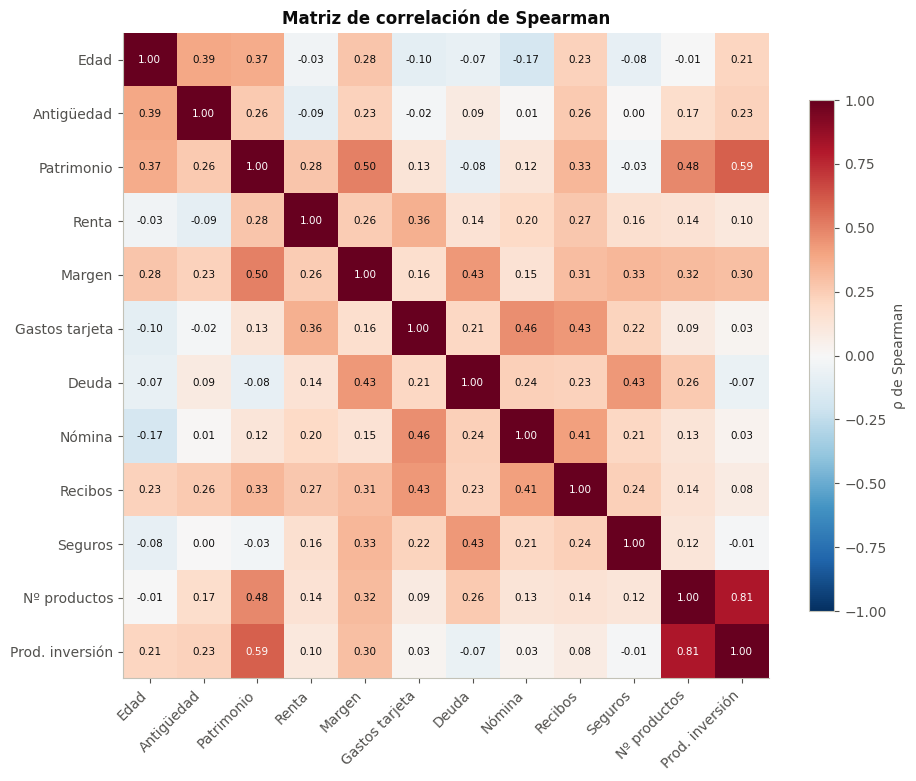

,Variable 1,Variable 2,rho,|rho|
131,Nº productos,Prod. inversión,0.807,0.807
35,Patrimonio,Prod. inversión,0.594,0.594
28,Patrimonio,Margen,0.501,0.501
34,Patrimonio,Nº productos,0.480,0.480
67,Gastos tarjeta,Nómina,0.463,0.463
68,Gastos tarjeta,Recibos,0.434,0.434
81,Deuda,Seguros,0.433,0.433
54,Margen,Deuda,0.430,0.430
92,Nómina,Recibos,0.412,0.412
1,Edad,Antigüedad,0.385,0.385


In [3]:
VARS_CORR = {
    'edad': 'Edad', 'antig': 'Antigüedad', 'totalpasta': 'Patrimonio', 'renta_final': 'Renta',
    'margecomercialut': 'Margen', 'gastos': 'Gastos tarjeta', 'deuda_total': 'Deuda', 'nominaimp': 'Nómina',
    'rdom': 'Recibos', 'total_proteccio': 'Seguros', 'total_productos_activos': 'Nº productos',
    'num_prod_inversion': 'Prod. inversión',
}
corr = d[list(VARS_CORR)].rename(columns=VARS_CORR).corr(method='spearman')

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right'); ax.set_yticks(range(len(corr)), corr.index)
for (i, j), v in np.ndenumerate(corr.values):
    ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7.5, color='white' if abs(v) > 0.55 else TINTA)
ax.grid(False); ax.set_title('Matriz de correlación de Spearman')
fig.colorbar(im, ax=ax, shrink=0.75, label='ρ de Spearman')
plt.tight_layout(); plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('rho').reset_index().rename(columns={'level_0': 'Variable 1', 'level_1': 'Variable 2'}))
pares['|rho|'] = pares['rho'].abs()
pares.sort_values('|rho|', ascending=False).head(10).round(3)

## 3. ¿Qué distingue a los clientes que invierten?
Se compara cada variable con `tiene_inversion`. Hay dos métodos según el tipo de variable:

- **Variables numéricas:** AUC univariante (0,5 = no distingue nada, 1 = distingue perfectamente) y prueba de Mann-Whitney (¿la diferencia es estadísticamente significativa?).
- **Variables categóricas:** chi-cuadrado y **V de Cramér**, que mide de 0 a 1 la fuerza de la asociación.

**Lectura de resultados.** Entre las variables numéricas, el patrimonio (AUC 0,85), el margen (0,67), la antigüedad (0,64) y la edad (0,62) separan bien a quien invierte de quien no; el Nº de productos tiene AUC 0,98 pero es casi tautológico (los productos de inversión forman parte de ese recuento), por eso se excluye del modelo. Entre las categóricas destacan el grupo de antigüedad (V = 0,23), el nivel de renta (0,22), el rango de edad (0,21) y la comunidad autónoma (0,20). La nómina domiciliada apenas discrimina (V = 0,018, p = 0,07): **domiciliar la nómina no convierte al cliente en inversor**. El cruce renta × perfil muestra el rango completo: un Conservador de renta baja invierte en el 12,0 % de los casos, frente al 63,7 % de un Pensionado de renta medio-alta.

      Variable   AUC              Dirección  Mediana inversores  Mediana no inversores  p-valor
  Nº productos 0.976 Más alto en inversores               4.000                  1.000    0.000
    Patrimonio 0.850 Más alto en inversores           24189.390                778.420    0.000
        Margen 0.665 Más alto en inversores              87.810                 24.180    0.000
    Antigüedad 0.635 Más alto en inversores             173.000                102.000    0.000
          Edad 0.620 Más alto en inversores              56.000                 46.000    0.000
         Renta 0.558 Más alto en inversores           16521.862              15547.843    0.000
       Recibos 0.541 Más alto en inversores               6.000                  4.000    0.000
         Deuda 0.527 Más bajo en inversores               0.000                  0.000    0.000
        Nómina 0.515 Más alto en inversores               0.000                  0.000    0.001
Gastos tarjeta 0.512 Más alto en inverso

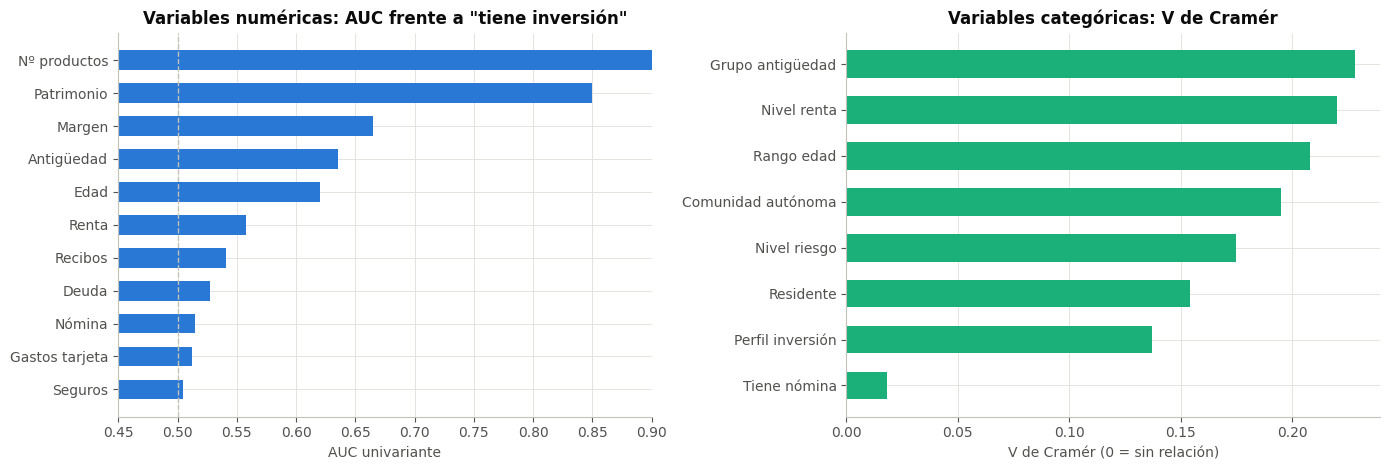

In [4]:
filas = []
for col, nombre in VARS_CORR.items():
    if col in ('num_prod_inversion',):
        continue
    x = d[col].fillna(0)
    auc = roc_auc_score(d['tiene_inversion'], x)
    p = stats.mannwhitneyu(x[d['tiene_inversion'] == 1], x[d['tiene_inversion'] == 0]).pvalue
    filas.append({'Variable': nombre, 'AUC': round(max(auc, 1 - auc), 3),
                  'Dirección': 'Más alto en inversores' if auc >= 0.5 else 'Más bajo en inversores',
                  'Mediana inversores': x[d['tiene_inversion'] == 1].median(),
                  'Mediana no inversores': x[d['tiene_inversion'] == 0].median(), 'p-valor': p})
num_inv = pd.DataFrame(filas).sort_values('AUC', ascending=False)

def cramers_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2, p, _, _ = stats.chi2_contingency(tabla)
    n = tabla.values.sum(); r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1))), p

CATEGORICAS = {'perfil': 'Perfil inversión', 'rango_edad': 'Rango edad', 'nivel_renta': 'Nivel renta',
               'grupo_antiguedad': 'Grupo antigüedad', 'tiene_nomina': 'Tiene nómina', 'residente': 'Residente',
               'nivel_riesgo': 'Nivel riesgo', 'comunidad_autonoma': 'Comunidad autónoma'}
cat_inv = pd.DataFrame([{'Variable': n, 'V de Cramér': round(cramers_v(d[c], d['tiene_inversion'])[0], 3),
                         'p-valor': cramers_v(d[c], d['tiene_inversion'])[1]} for c, n in CATEGORICAS.items()]
                       ).sort_values('V de Cramér', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
a = num_inv.sort_values('AUC')
axes[0].barh(a['Variable'], a['AUC'], color=COLORES[0], height=0.6)
axes[0].axvline(0.5, color=GRIS, ls='--', lw=1); axes[0].set_xlim(0.45, 0.9)
axes[0].set_title('Variables numéricas: AUC frente a "tiene inversión"'); axes[0].set_xlabel('AUC univariante')
b = cat_inv.sort_values('V de Cramér')
axes[1].barh(b['Variable'], b['V de Cramér'], color=COLORES[2], height=0.6)
axes[1].set_title('Variables categóricas: V de Cramér'); axes[1].set_xlabel('V de Cramér (0 = sin relación)')
plt.tight_layout(); plt.show()

print(num_inv.round(3).to_string(index=False)); print(); print(cat_inv.round(4).to_string(index=False))

In [5]:
# Tasa de inversión por combinación de nivel de renta y perfil (base del mapa de calor del Power BI)
orden_renta = ['Sin datos', 'Bajo', 'Medio-Bajo', 'Medio', 'Medio-Alto', 'Alto']
tasa = (d.pivot_table(index='nivel_renta', columns='perfil', values='tiene_inversion', aggfunc='mean')
        .reindex(index=orden_renta, columns=['Juvenil', 'Conservador', 'Pensionado']) * 100).round(1)
clientes = d.pivot_table(index='nivel_renta', columns='perfil', values='id_cliente', aggfunc='count').reindex(
    index=orden_renta, columns=['Juvenil', 'Conservador', 'Pensionado'])
print("% de clientes con inversión (filas: nivel de renta, columnas: perfil)")
print(tasa.to_string()); print("\nNº de clientes"); print(clientes.fillna(0).astype(int).to_string())

% de clientes con inversión (filas: nivel de renta, columnas: perfil)
perfil       Juvenil  Conservador  Pensionado
nivel_renta                                  
Sin datos        NaN          NaN        20.0
Bajo            23.6         12.0        25.6
Medio-Bajo      32.4         22.7        36.7
Medio           37.5         32.8        42.0
Medio-Alto      31.6         44.4        63.7
Alto            33.3         33.3        42.9

Nº de clientes
perfil       Juvenil  Conservador  Pensionado
nivel_renta                                  
Sin datos          0            0           5
Bajo             602          732        2662
Medio-Bajo       102          203        2856
Medio             48           58        1961
Medio-Alto        19           18         515
Alto               3            3          35


## 4. Segmentación de clientes: LOF + K-Means + PCA
Sigue el proceso del Módulo 7:
1. Variables de comportamiento estandarizadas, con logaritmo en los importes.
2. **LOF** marca el 2 % de clientes atípicos, que no entran en el ajuste.
3. Se elige **K** con el codo y la silhouette.
4. Los segmentos se **nombran por reglas sobre su perfil**, para que el resultado sea estable entre ejecuciones.

**Lectura de resultados.** LOF aparta 197 clientes atípicos (2 %) para que no deformen los centroides. Con el resto se elige **K = 5**: aunque K = 2 tiene mejor silhouette (0,27), solo separa jóvenes de adultos y no aporta nada accionable; K = 5 mantiene una silhouette similar a K = 4–8 (≈ 0,20) y da cinco grupos con lectura de negocio clara: *Ahorradores senior* (2.033 clientes, 82 % con inversión, 31,6 % del margen), *Hipotecados* (1.400, 42,0 % del margen), *Transaccionales con nómina* (2.029, 13,3 % del margen), *Poco vinculados* (3.018, solo 10,1 % del margen y 14,7 % con inversión) y *Jóvenes vinculados* (1.145). Una silhouette de 0,20 indica grupos que se solapan en los bordes, algo habitual en datos de clientes; por eso los segmentos se usan como orientación comercial, no como fronteras rígidas.

Atípicos LOF: 197 clientes


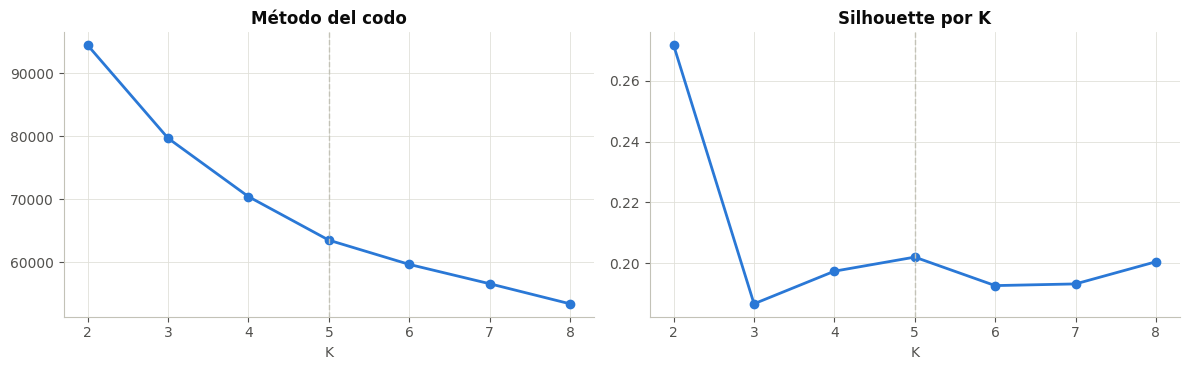

,K,Inercia,Silhouette
0,2,94474.809,0.272
1,3,79711.111,0.187
2,4,70440.620,0.197
3,5,63531.202,0.202
4,6,59683.866,0.193
5,7,56616.766,0.193
6,8,53427.637,0.200


In [6]:
CAT = {
    'Cuentas': ['ind_cuentaexpansion', 'ind_cuentaexpansionnegocios', 'ind_cuentaexpansionpremium', 'ind_cuentaexperiencia',
                'ind_cuentaprimera', 'ind_cuentaproyeccion', 'ind_altrescc'],
    'Tarjetas': [c for c in d.columns if c.startswith('ind_cv')],
    'Financiacion': ['ind_credf', 'ind_credv', 'ind_hipfix', 'ind_hipmixt', 'ind_hipoteca', 'ind_hipvar', 'ind_promotor', 'ind_rentvehic'],
}
for k, cols in CAT.items():
    d['n_' + k.lower()] = d[cols].sum(axis=1)
L = np.log1p
X_seg = pd.DataFrame({
    'edad': d['edad'], 'antiguedad': d['antig'], 'log_patrimonio': L(d['totalpasta'].clip(lower=0)),
    'log_renta': L(d['renta_final']), 'margen_log': np.sign(d['margecomercialut']) * L(d['margecomercialut'].abs()),
    'log_gastos': L(d['gastos'].fillna(0)), 'log_deuda': L(d['deuda_total']), 'log_nomina': L(d['nominaimp']),
    'n_cuentas': d['n_cuentas'], 'n_tarjetas': d['n_tarjetas'], 'n_financiacion': d['n_financiacion'],
    'n_inversion': d['num_prod_inversion']})
Z = StandardScaler().fit_transform(X_seg)
d['atipico'] = (LocalOutlierFactor(n_neighbors=35, contamination=0.02).fit_predict(Z) == -1).astype(int)
Zn = Z[d['atipico'] == 0]

res_k = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Zn)
    res_k.append({'K': k, 'Inercia': m.inertia_,
                  'Silhouette': silhouette_score(Zn, m.labels_, sample_size=4000, random_state=RANDOM_STATE)})
res_k = pd.DataFrame(res_k)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(res_k['K'], res_k['Inercia'], marker='o', color=COLORES[0], lw=2); axes[0].set_title('Método del codo')
axes[1].plot(res_k['K'], res_k['Silhouette'], marker='o', color=COLORES[0], lw=2); axes[1].set_title('Silhouette por K')
for ax in axes:
    ax.axvline(5, color=GRIS, ls='--', lw=1); ax.set_xlabel('K')
plt.tight_layout(); plt.show()
print(f"Atípicos LOF: {d['atipico'].sum()} clientes"); res_k.round(3)

In [7]:
K = 5
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Zn)
d['cluster'] = -1
d.loc[d['atipico'] == 0, 'cluster'] = km.labels_
perfil_k = (d[d['cluster'] >= 0].assign(con_fin=lambda x: (x['n_financiacion'] > 0).astype(int),
                                         con_nom=lambda x: (x['nominaimp'] > 0).astype(int))
            .groupby('cluster').agg(clientes=('id_cliente', 'size'), edad=('edad', 'median'), pat=('totalpasta', 'median'),
                                    inv=('tiene_inversion', 'mean'), fin=('con_fin', 'mean'), nom=('con_nom', 'mean')))

def nombrar(p):
    nombres, libres = {}, list(p.index)
    def tomar(i, n):
        nombres[i] = n; libres.remove(i)
    tomar(p.loc[libres, 'edad'].idxmin(), 'Jóvenes vinculados')
    tomar(p.loc[libres, 'inv'].idxmax(), 'Ahorradores senior')
    tomar(p.loc[libres, 'fin'].idxmax(), 'Hipotecados')
    tomar(p.loc[libres, 'nom'].idxmax(), 'Transaccionales con nómina')
    tomar(libres[0], 'Poco vinculados')
    return nombres

d['segmento_ml'] = d['cluster'].map(nombrar(perfil_k)).fillna('Atípico')
ORDEN_SEG = ['Jóvenes vinculados', 'Poco vinculados', 'Hipotecados', 'Transaccionales con nómina', 'Ahorradores senior', 'Atípico']
resumen_seg = (d.groupby('segmento_ml').agg(Clientes=('id_cliente', 'size'), Edad_mediana=('edad', 'median'),
                                            Patrimonio_mediano=('totalpasta', 'median'), Margen_medio=('margecomercialut', 'mean'),
                                            Pct_inversion=('tiene_inversion', 'mean'), Productos_medios=('total_productos_activos', 'mean'))
               .reindex(ORDEN_SEG))
resumen_seg['Pct_inversion'] = (resumen_seg['Pct_inversion'] * 100).round(1)
print(f"Silhouette K = {K}: {silhouette_score(Zn, km.labels_, sample_size=4000, random_state=RANDOM_STATE):.3f}")
resumen_seg.round(1)

Silhouette K = 5: 0.202


,Clientes,Edad_mediana,Patrimonio_mediano,Margen_medio,Pct_inversion,Productos_medios
segmento_ml,,,,,,
Jóvenes vinculados,1145,16.0,265.8,5.7,18.4,2.4
Poco vinculados,3018,54.0,658.6,41.8,14.7,0.7
Hipotecados,1400,45.0,1625.8,376.8,26.6,3.4
Transaccionales con nómina,2029,43.0,2410.3,82.5,24.5,1.7
Ahorradores senior,2033,68.0,43435.6,195.2,82.5,3.7
Atípico,197,39.0,864.5,156.7,30.5,2.8


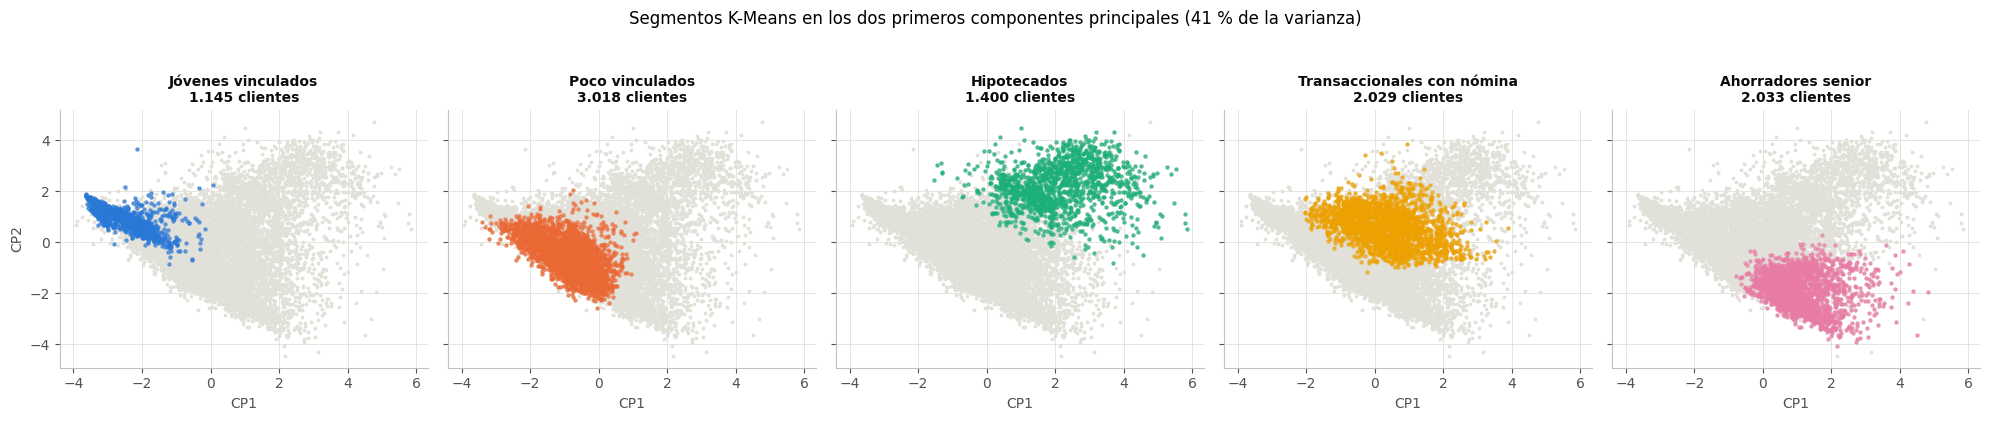

perfil,Conservador,Juvenil,Pensionado,Total
segmento_ml,,,,
Jóvenes vinculados,349,690,106,1145
Poco vinculados,218,37,2763,3018
Hipotecados,63,0,1337,1400
Transaccionales con nómina,318,9,1702,2029
Ahorradores senior,15,1,2017,2033
Atípico,51,37,109,197
Total,1014,774,8034,9822


In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(Z)
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, nombre, color in zip(axes, ORDEN_SEG[:5], COLORES):
    ax.scatter(coords[:, 0], coords[:, 1], s=3, color=REJILLA, rasterized=True)
    m = (d['segmento_ml'] == nombre).values
    ax.scatter(coords[m, 0], coords[m, 1], s=5, color=color, alpha=0.6, rasterized=True)
    ax.set_title(f"{nombre}\n{m.sum():,} clientes".replace(',', '.'), fontsize=10); ax.set_xlabel('CP1')
axes[0].set_ylabel('CP2')
plt.suptitle(f'Segmentos K-Means en los dos primeros componentes principales '
             f'({pca.explained_variance_ratio_.sum() * 100:.0f} % de la varianza)', y=1.04)
plt.tight_layout(); plt.show()
pd.crosstab(d['segmento_ml'], d['perfil'], margins=True, margins_name='Total').reindex(ORDEN_SEG + ['Total'])

## 5. Modelo de propensión a invertir
- **Objetivo:** `tiene_inversion`.
- **Variables excluidas para evitar fugas de información:**
  - los productos de inversión;
  - el nº total de productos;
  - el patrimonio y el margen, que se deben en parte a tener inversión;
  - las puntuaciones internas `sio_*`, porque `sio_ahorro` contiene la respuesta (AUC 0,999).
- **Metodología:** 75 % entrenamiento / 25 % test estratificado, `class_weight='balanced'` y cuatro modelos comparados.

**Lectura de resultados.** Los cuatro modelos tienen un poder de discriminación parecido (AUC entre 0,76 y 0,78). Se elige la **regresión logística** (AUC 0,757) porque tiene el mayor recall (70,3 %: detecta 7 de cada 10 futuros inversores, que es lo que interesa en una campaña) y porque sus coeficientes se pueden explicar a negocio. SVM y Random Forest ganan solo 2 puntos de AUC a cambio de perder interpretabilidad y recall. Se excluyeron variables con fuga de información (el propio saldo de inversión, el patrimonio total y el margen, que ya contienen el producto que queremos predecir). Los coeficientes indican que la residencia, el nivel de renta, la edad y la antigüedad empujan hacia la inversión, mientras que el saldo deudor, la renta imputada y la deuda la frenan. Resultado operativo: **1.313 clientes en banda Alta** de propensión que aún no invierten (umbral global); si la banda se calcula dentro de cada perfil, salen 1.027 Pensionados, 171 Conservadores y 116 Juveniles — es el listado priorizado de la página *Segmentos y propensión* del Power BI.

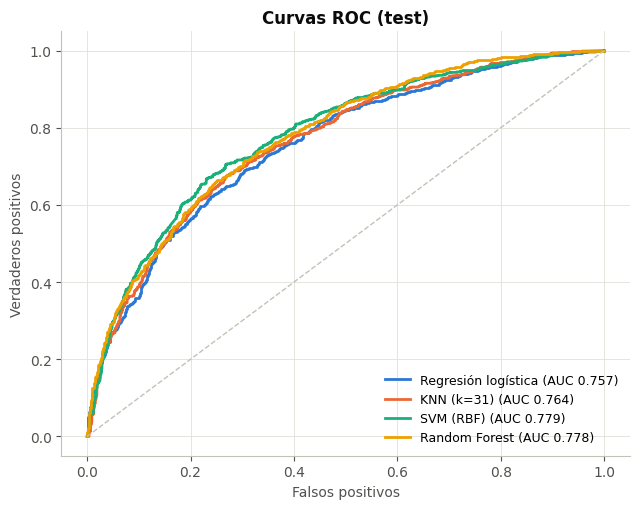

,AUC,Recall,Precisión,F1,Accuracy
Modelo,,,,,
Regresión logística,0.757,0.703,0.513,0.593,0.680
KNN (k=31),0.764,0.477,0.637,0.546,0.736
SVM (RBF),0.779,0.564,0.621,0.591,0.741
Random Forest,0.778,0.659,0.569,0.611,0.721


In [9]:
VARS_MODELO = {
    'edad': d['edad'], 'antiguedad': d['antig'], 'nivel_renta': d['nivren'], 'log_renta': L(d['renta_final']),
    'renta_imputada': d['renta_imputada'], 'residente': d['residente'],
    'tiene_datos_familia': d['tipofamilia'].notna().astype(int), 'miembros_familia': d['miembrosfamilia'].fillna(0),
    'log_nomina': L(d['nominaimp']), 'recibos_domiciliados': d['rdom'], 'tpv': d['tpv'], 'seguros': d['total_proteccio'],
    'log_gastos': L(d['gastos'].fillna(0)), 'log_deuda': L(d['deuda_total']), 'log_pos_deudora': L(d['impoped']),
    'n_cuentas': d['n_cuentas'], 'n_tarjetas': d['n_tarjetas'], 'n_financiacion': d['n_financiacion'],
}
X = pd.DataFrame(VARS_MODELO).astype(float)
y = d['tiene_inversion'].astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
MODELOS = {
    'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000)),
    'KNN (k=31)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=31, weights='distance')),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=RANDOM_STATE)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
}
met, probs = [], {}
for n, m in MODELOS.items():
    m.fit(X_tr, y_tr); p = m.predict_proba(X_te)[:, 1]; pred = (p >= 0.5).astype(int); probs[n] = p
    met.append({'Modelo': n, 'AUC': roc_auc_score(y_te, p), 'Recall': recall_score(y_te, pred),
                'Precisión': precision_score(y_te, pred), 'F1': f1_score(y_te, pred), 'Accuracy': accuracy_score(y_te, pred)})
met = pd.DataFrame(met).set_index('Modelo')
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for (n, p), c in zip(probs.items(), COLORES):
    fpr, tpr, _ = roc_curve(y_te, p); ax.plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC {met.loc[n, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1); ax.legend(frameon=False, fontsize=9, loc='lower right')
ax.set_title('Curvas ROC (test)'); ax.set_xlabel('Falsos positivos'); ax.set_ylabel('Verdaderos positivos')
plt.tight_layout(); plt.show()
met.round(3)

banda_en_perfil  Alta  Media  Baja  Ya invierte
perfil                                         
Conservador       171    255   426          162
Juvenil           116    171   287          200
Pensionado       1027   1544  2564         2899


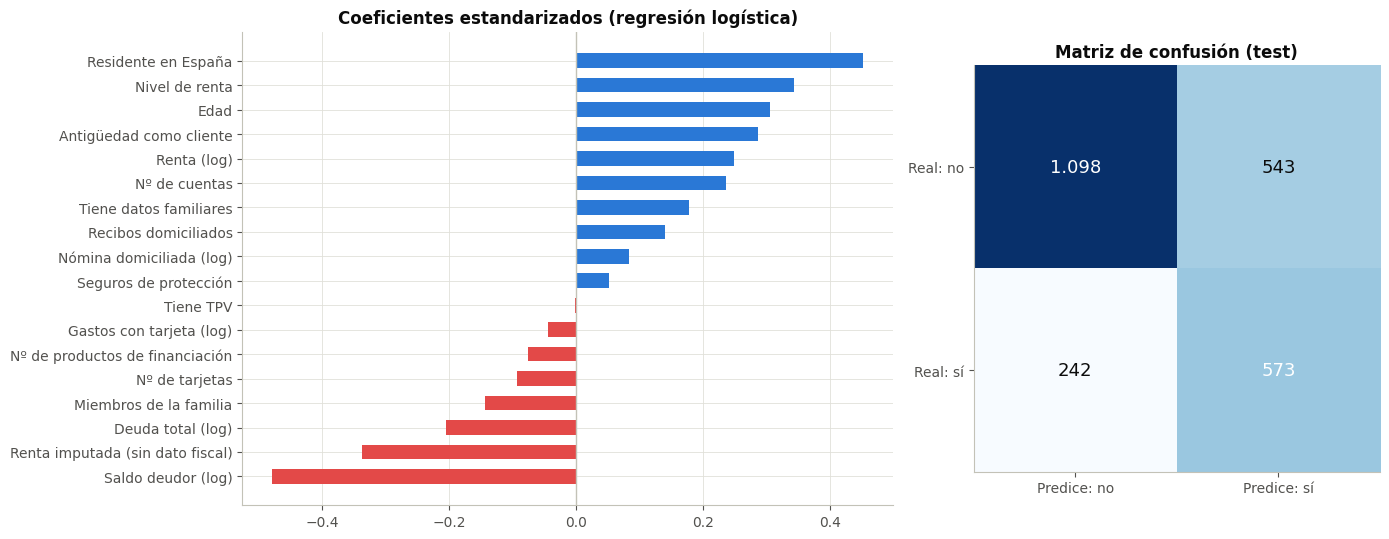

,Variable,Coeficiente,Odds ratio,Efecto
5,Residente en España,0.452,1.571,Aumenta la probabilidad
2,Nivel de renta,0.344,1.410,Aumenta la probabilidad
0,Edad,0.305,1.356,Aumenta la probabilidad
1,Antigüedad como cliente,0.286,1.331,Aumenta la probabilidad
3,Renta (log),0.249,1.282,Aumenta la probabilidad
15,Nº de cuentas,0.236,1.266,Aumenta la probabilidad
6,Tiene datos familiares,0.177,1.194,Aumenta la probabilidad
9,Recibos domiciliados,0.139,1.149,Aumenta la probabilidad
8,Nómina domiciliada (log),0.084,1.088,Aumenta la probabilidad
11,Seguros de protección,0.052,1.053,Aumenta la probabilidad


In [10]:
ELEGIDO = 'Regresión logística'
logit = MODELOS[ELEGIDO][-1]
DESCRIPCION_VAR = {
    'edad': 'Edad', 'antiguedad': 'Antigüedad como cliente', 'nivel_renta': 'Nivel de renta', 'log_renta': 'Renta (log)',
    'renta_imputada': 'Renta imputada (sin dato fiscal)', 'residente': 'Residente en España',
    'tiene_datos_familia': 'Tiene datos familiares', 'miembros_familia': 'Miembros de la familia',
    'log_nomina': 'Nómina domiciliada (log)', 'recibos_domiciliados': 'Recibos domiciliados', 'tpv': 'Tiene TPV',
    'seguros': 'Seguros de protección', 'log_gastos': 'Gastos con tarjeta (log)', 'log_deuda': 'Deuda total (log)',
    'log_pos_deudora': 'Saldo deudor (log)', 'n_cuentas': 'Nº de cuentas', 'n_tarjetas': 'Nº de tarjetas',
    'n_financiacion': 'Nº de productos de financiación'}
coefs = pd.DataFrame({'Variable': [DESCRIPCION_VAR[c] for c in X.columns], 'Coeficiente': logit.coef_[0]})
coefs['Odds ratio'] = np.exp(coefs['Coeficiente'])
coefs['Efecto'] = np.where(coefs['Coeficiente'] >= 0, 'Aumenta la probabilidad', 'Reduce la probabilidad')
coefs = coefs.sort_values('Coeficiente')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].barh(coefs['Variable'], coefs['Coeficiente'], color=np.where(coefs['Coeficiente'] >= 0, COLORES[0], '#e34948'), height=0.6)
axes[0].axvline(0, color=GRIS, lw=1); axes[0].set_title('Coeficientes estandarizados (regresión logística)')
cm = confusion_matrix(y_te, (probs[ELEGIDO] >= 0.5).astype(int))
axes[1].imshow(cm, cmap='Blues'); axes[1].grid(False)
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f'{v:,}'.replace(',', '.'), ha='center', va='center', color='white' if v > cm.max() / 2 else TINTA, fontsize=13)
axes[1].set_xticks([0, 1], ['Predice: no', 'Predice: sí']); axes[1].set_yticks([0, 1], ['Real: no', 'Real: sí'])
axes[1].set_title('Matriz de confusión (test)')
plt.tight_layout(); plt.show()

# Puntuación de toda la cartera y bandas de propensión
d['prob_inversion'] = MODELOS[ELEGIDO].predict_proba(X)[:, 1].round(4)
no_inv = d['tiene_inversion'] == 0
q50, q80 = d.loc[no_inv, 'prob_inversion'].quantile([0.5, 0.8])
d['banda_propension'] = np.where(~no_inv, 'Ya invierte', np.where(d['prob_inversion'] >= q80, 'Alta',
                                 np.where(d['prob_inversion'] >= q50, 'Media', 'Baja')))
def banda_rel(g):
    a, b = g.quantile([0.5, 0.8])
    return pd.Series(np.where(g >= b, 'Alta', np.where(g >= a, 'Media', 'Baja')), index=g.index)
d['banda_en_perfil'] = 'Ya invierte'
d.loc[no_inv, 'banda_en_perfil'] = d[no_inv].groupby('perfil')['prob_inversion'].transform(banda_rel)
print(pd.crosstab(d['perfil'], d['banda_en_perfil']).reindex(columns=['Alta', 'Media', 'Baja', 'Ya invierte']).to_string())
coefs.sort_values('Coeficiente', ascending=False).round(3)

## 6. Exportación del modelo de datos para Power BI
Se genera `PowerBI/TFM_Ethos_datos.xlsx` con un **modelo en estrella**. Power BI lo carga con Power Query a través del parámetro `RutaDatos`.

| Hoja | Grano | Uso en el informe |
|---|---|---|
| `Clientes` | 1 fila por cliente (9.822) | Tabla central: atributos, importes, segmentos y propensión |
| `Geografia` | Provincia | Dimensión geográfica (provincia y comunidad autónoma) |
| `Productos` | Producto (45) | Catálogo con categoría |
| `ClienteProducto` | Cliente × producto contratado | Penetración de productos y cesta |
| `Perfiles` | Perfil de inversión | Producto objetivo de cada perfil (objetivo 3) |
| `SegmentosML` | Segmento K-Means | Descripción de los segmentos |
| `Correlaciones` | Par de variables | Mapa de calor de Spearman |
| `FactoresInversion` | Variable | AUC y V de Cramér frente a la inversión |
| `ModeloMetricas` | Modelo | Comparativa de los 4 modelos |
| `ModeloCoeficientes` | Variable | Peso de cada variable en la regresión logística |
| `SeleccionK` | K | Codo y silhouette |
| `KPIs` | KPI | Glosario de KPIs (Entregas 2 y 3) |

In [11]:
SALIDA.parent.mkdir(parents=True, exist_ok=True)
ORD_ANT = {'≤1 año': 1, '1-3 años': 2, '3-5 años': 3, '5-10 años': 4, '10-20 años': 5, '>20 años': 6}
ORD_RIESGO = {'Bajo': 1, 'Moderado': 2, 'Alto': 3, 'Crítico': 4, 'Sin patrimonio': 5}
ORD_BANDA = {'Alta': 1, 'Media': 2, 'Baja': 3, 'Ya invierte': 4}
d['ranking_patrimonio'] = d['totalpasta'].rank(ascending=False, method='first').astype(int)

clientes_pbi = pd.DataFrame({
    'ID cliente': d['id_cliente'], 'Edad': d['edad'], 'Rango edad': d['rango_edad'],
    'Orden rango edad': d['rango_edad'].map({e: i for i, e in enumerate(ETQ_EDAD, 1)}),
    'Perfil inversión': d['perfil'], 'Segmento edad': d['segmento_edad'],
    'Nivel renta': d['nivel_renta'], 'Orden nivel renta': d['nivren'].fillna(0).astype(int),
    'Código provincia': d['prov'], 'Residente': np.where(d['residente'] == 1, 'Residente', 'No residente'),
    'Tipo familia': d['tipofamilia'].fillna('Sin dato'), 'Miembros familia': d['miembrosfamilia'],
    'Antigüedad (años)': d['antiguedad_anios'], 'Grupo antigüedad': d['grupo_antiguedad'],
    'Orden antigüedad': d['grupo_antiguedad'].map(ORD_ANT), 'Año apertura': d['anio_apertura'],
    'Década apertura': d['decada_apertura'],
    'Patrimonio': d['totalpasta'].round(2), 'Tramo patrimonio': d['tramo_patrimonio'],
    'Orden tramo patrimonio': d['tramo_patrimonio'].map({e: i for i, e in enumerate(ETQ_PAT, 1)}),
    'Renta': d['renta_final'].round(2), 'Renta imputada': si_no(d['renta_imputada'] == 1),
    'Gastos tarjeta': d['gastos'].round(2), 'Margen comercial': d['margecomercialut'].round(2),
    'Crédito': d['credit'].round(2), 'Revolving': d['revolving'].round(2), 'Hipoteca': d['tothipo'].round(2),
    'Deuda total': d['deuda_total'].round(2), 'Ratio endeudamiento': d['ratio_endeudamiento'],
    'Nivel riesgo': d['nivel_riesgo'], 'Orden nivel riesgo': d['nivel_riesgo'].map(ORD_RIESGO),
    'Nómina': d['nominaimp'].round(2), 'Tiene nómina': d['tiene_nomina'], 'Recibos domiciliados': d['rdom'],
    'Seguros protección': d['total_proteccio'], 'Nº productos': d['total_productos_activos'],
    'Tramo productos': d['tramo_productos'], 'Orden tramo productos': d['total_productos_activos'].clip(upper=5),
    'Mono-producto': si_no(d['total_productos_activos'] == 1), 'Nº productos inversión': d['num_prod_inversion'],
    'Tiene inversión': si_no(d['tiene_inversion'] == 1), 'Segmento ML': d['segmento_ml'],
    'Atípico': si_no(d['atipico'] == 1), 'Probabilidad inversión': d['prob_inversion'],
    'Banda propensión': d['banda_propension'], 'Orden banda': d['banda_propension'].map(ORD_BANDA),
    'Banda en perfil': d['banda_en_perfil'], 'Ranking patrimonio': d['ranking_patrimonio'],
    'Top 100 patrimonio': si_no(d['ranking_patrimonio'] <= 100),
    'SIO vinculación': d['sio_vinculacion'].round(4), 'SIO desvinculación': d['sio_desvinculacion'].round(4),
})

PROVINCIAS = (d[['prov', 'provincia_nombre', 'comunidad_autonoma', 'es_extranjero']].drop_duplicates('prov')
              .sort_values('prov'))
geografia_pbi = pd.DataFrame({'Código provincia': PROVINCIAS['prov'], 'Provincia': PROVINCIAS['provincia_nombre'],
                              'Comunidad autónoma': PROVINCIAS['comunidad_autonoma'],
                              'Ámbito': np.where(PROVINCIAS['es_extranjero'] == 1, 'Extranjero', 'España')})

CATALOGO = {
    'ind_cuentaexpansion': ('Cuenta Expansión', 'Cuentas'), 'ind_cuentaexpansionnegocios': ('Cuenta Expansión Negocios', 'Cuentas'),
    'ind_cuentaexpansionpremium': ('Cuenta Expansión Premium', 'Cuentas'), 'ind_cuentaexperiencia': ('Cuenta Experiencia', 'Cuentas'),
    'ind_cuentaprimera': ('Cuenta Primera', 'Cuentas'), 'ind_cuentaproyeccion': ('Cuenta Proyección', 'Cuentas'),
    'ind_altrescc': ('Otras cuentas corrientes', 'Cuentas'),
    'ind_cvautonomos': ('Tarjeta CV Autónomos', 'Tarjetas'), 'ind_cvdirect': ('Tarjeta CV Direct', 'Tarjetas'),
    'ind_cvhabit': ('Tarjeta CV Habit', 'Tarjetas'), 'ind_cvjove': ('Tarjeta CV Jove', 'Tarjetas'),
    'ind_cvjunior': ('Tarjeta CV Junior', 'Tarjetas'), 'ind_cvmas': ('Tarjeta CV Más', 'Tarjetas'),
    'ind_cvprestige': ('Tarjeta CV Prestige', 'Tarjetas'), 'ind_cvsenior': ('Tarjeta CV Senior', 'Tarjetas'),
    'ind_estalinv': ('Estalvi Inversión (indicador resumen)', 'Inversión y ahorro'), 'ind_estalvi': ('Estalvi (Ahorro)', 'Inversión y ahorro'),
    'ind_asvidaestgarcol': ('Seguro Vida Ahorro Garantizado Colectivo', 'Inversión y ahorro'),
    'ind_asvidaestulinkc': ('Seguro Vida Ahorro Unit Linked Colectivo', 'Inversión y ahorro'),
    'ind_bonsestruc': ('Bonos estructurados', 'Inversión y ahorro'), 'ind_cialp': ('CIALP (Cuenta Individual Ahorro L/P)', 'Inversión y ahorro'),
    'ind_diposit': ('Depósitos', 'Inversión y ahorro'), 'ind_fi': ('Fondos de inversión', 'Inversión y ahorro'),
    'ind_fialtent': ('Fondos de inversión alternativos', 'Inversión y ahorro'), 'ind_gcfisbp': ('Gestión de carteras', 'Inversión y ahorro'),
    'ind_gransel': ('Gran Selección', 'Inversión y ahorro'), 'ind_pp': ('Planes de pensiones', 'Inversión y ahorro'),
    'ind_ppassoci': ('Planes de pensiones asociados', 'Inversión y ahorro'), 'ind_ppemp': ('Planes de pensiones de empleo', 'Inversión y ahorro'),
    'ind_pprest': ('Planes de previsión (prestaciones)', 'Inversión y ahorro'), 'ind_rentvitindiv': ('Renta vitalicia individual', 'Inversión y ahorro'),
    'ind_renttempcol': ('Renta temporal colectiva', 'Inversión y ahorro'), 'ind_renttempind': ('Renta temporal individual', 'Inversión y ahorro'),
    'ind_restorvrf': ('Resto renta variable / fija', 'Inversión y ahorro'), 'ind_rfixaval': ('Renta fija', 'Inversión y ahorro'),
    'ind_vrdafix': ('Valores de renta fija', 'Inversión y ahorro'),
    'ind_credf': ('Crédito', 'Financiación'), 'ind_credv': ('Crédito vivienda', 'Financiación'), 'ind_hipfix': ('Hipoteca tipo fijo', 'Financiación'),
    'ind_hipmixt': ('Hipoteca tipo mixto', 'Financiación'), 'ind_hipoteca': ('Hipoteca', 'Financiación'),
    'ind_hipvar': ('Hipoteca tipo variable', 'Financiación'), 'ind_promotor': ('Préstamo promotor', 'Financiación'),
    'ind_rentvehic': ('Renting de vehículo', 'Financiación'), 'ind_varispassiu': ('Otros productos de pasivo', 'Otros'),
}
productos_pbi = pd.DataFrame([{'Código producto': c, 'Producto': n, 'Categoría': cat,
                               'Indicador resumen': 'Sí' if c == 'ind_estalinv' else 'No'} for c, (n, cat) in CATALOGO.items()])
cp = d[['id_cliente'] + list(CATALOGO)].melt(id_vars='id_cliente', var_name='Código producto', value_name='v')
cliente_producto_pbi = cp[cp['v'] == 1].drop(columns='v').rename(columns={'id_cliente': 'ID cliente'}).sort_values(['ID cliente', 'Código producto'])

perfiles_pbi = pd.DataFrame([
    {'Perfil inversión': 'Juvenil', 'Rango de edad del perfil': '0 a 18 años', 'Producto objetivo': 'Inversión para estudios', 'Orden perfil': 1},
    {'Perfil inversión': 'Conservador', 'Rango de edad del perfil': '19 a 30 años', 'Producto objetivo': 'Inversión primera vivienda', 'Orden perfil': 2},
    {'Perfil inversión': 'Pensionado', 'Rango de edad del perfil': 'Más de 30 años', 'Producto objetivo': 'Inversión para la jubilación', 'Orden perfil': 3}])
DESC_SEG = {
    'Jóvenes vinculados': 'Menores o muy jóvenes con cuenta y tarjeta junior', 'Poco vinculados': 'Adultos con muy pocos productos, poco patrimonio y poco margen',
    'Hipotecados': 'Clientes con hipoteca o financiación, alta deuda y el mayor margen', 'Transaccionales con nómina': 'Mediana edad, nómina domiciliada y uso diario de la cuenta',
    'Ahorradores senior': 'Mayores, muy antiguos, alto patrimonio y mayoría con inversión', 'Atípico': 'Combinaciones poco habituales detectadas por LOF'}
segmentos_pbi = pd.DataFrame([{'Segmento ML': s, 'Descripción segmento': DESC_SEG[s], 'Orden segmento': i} for i, s in enumerate(ORDEN_SEG, 1)])

correlaciones_pbi = corr.stack().rename('Correlación').reset_index().rename(columns={'level_0': 'Variable X', 'level_1': 'Variable Y'})
correlaciones_pbi['Orden X'] = correlaciones_pbi['Variable X'].map({v: i for i, v in enumerate(corr.columns, 1)})
correlaciones_pbi['Orden Y'] = correlaciones_pbi['Variable Y'].map({v: i for i, v in enumerate(corr.columns, 1)})
correlaciones_pbi['Correlación'] = correlaciones_pbi['Correlación'].round(3)

factores_pbi = pd.concat([
    num_inv.assign(Tipo='Numérica', Métrica='AUC univariante').rename(columns={'AUC': 'Valor'})[['Variable', 'Tipo', 'Métrica', 'Valor', 'Dirección']],
    cat_inv.assign(Tipo='Categórica', Métrica='V de Cramér', Dirección='Asociación').rename(columns={'V de Cramér': 'Valor'})[['Variable', 'Tipo', 'Métrica', 'Valor', 'Dirección']]])

metricas_pbi = met.reset_index().round(4); metricas_pbi['Seleccionado'] = np.where(metricas_pbi['Modelo'] == ELEGIDO, 'Sí', 'No')
coef_pbi = coefs.round(4)
seleccion_k_pbi = res_k.round(4)
kpis_pbi = pd.DataFrame([
    ('KPI_DISTRIBUCION_PRODUCTOS', 'Distribución de clientes por nº de productos', 'Clientes por nº de productos y % mono-producto', 'Productos y vinculación', 'Entrega 2'),
    ('KPI_ENDEUDAMIENTO', 'Ratio de endeudamiento', '(crédito + revolving + hipoteca) / patrimonio; % clientes con ratio > 1', 'Riesgo', 'Entrega 2'),
    ('KPI_POR_NIVEL_RENTA', 'Cartera por nivel de renta', 'Clientes, patrimonio, margen e inversión por nivel de renta', 'Clientes', 'Entrega 2'),
    ('KPI_POR_SEGMENTO', 'Comparativa de perfiles de inversión', 'Clientes, % margen e inversión por perfil', 'Resumen ejecutivo', 'Entrega 2'),
    ('KPI_PENETRACION_PRODUCTO', 'Penetración de producto', 'Clientes con el producto / total clientes', 'Productos y vinculación', 'Entrega 2'),
    ('KPI_POR_PROVINCIA', 'Cartera por provincia', 'Clientes, patrimonio y margen por provincia', 'Geografía', 'Entrega 2'),
    ('KPI_TOP_CLIENTES_PATRIMONIO', 'Concentración en el Top 100', 'Patrimonio Top 100 / patrimonio total', 'Resumen ejecutivo', 'Entrega 2'),
    ('KPI_PROPENSION_INVERSION', 'Mercado potencial de inversión', 'Clientes sin inversión con propensión Alta', 'Segmentación y propensión', 'Entrega 3'),
    ('KPI_INDICE_MARGEN', 'Índice de margen', 'Margen medio del grupo / margen medio de la cartera', 'Resumen ejecutivo', 'Entrega 3'),
    ('KPI_CLIENTES_SOBRE_UMBRAL', 'Clientes sobre el umbral de propensión', 'Clientes sin inversión con probabilidad ≥ umbral elegido', 'Segmentación y propensión', 'Entrega 3'),
], columns=['ID KPI', 'KPI', 'Fórmula', 'Página del informe', 'Entrega'])

HOJAS = {'Clientes': clientes_pbi, 'Geografia': geografia_pbi, 'Productos': productos_pbi, 'ClienteProducto': cliente_producto_pbi,
         'Perfiles': perfiles_pbi, 'SegmentosML': segmentos_pbi, 'Correlaciones': correlaciones_pbi, 'FactoresInversion': factores_pbi,
         'ModeloMetricas': metricas_pbi, 'ModeloCoeficientes': coef_pbi, 'SeleccionK': seleccion_k_pbi, 'KPIs': kpis_pbi}
with pd.ExcelWriter(SALIDA, engine='openpyxl') as w:
    for nombre, tabla in HOJAS.items():
        tabla.to_excel(w, sheet_name=nombre, index=False)
for nombre, tabla in HOJAS.items():
    print(f"{nombre:<20} {len(tabla):>6} filas x {tabla.shape[1]:>2} columnas")
print(f"\n✅ Modelo de datos exportado a {SALIDA}")

Clientes               9822 filas x 51 columnas
Geografia                53 filas x  4 columnas
Productos                45 filas x  4 columnas
ClienteProducto       21260 filas x  2 columnas
Perfiles                  3 filas x  4 columnas
SegmentosML               6 filas x  3 columnas
Correlaciones           144 filas x  5 columnas
FactoresInversion        19 filas x  5 columnas
ModeloMetricas            4 filas x  7 columnas
ModeloCoeficientes       18 filas x  4 columnas
SeleccionK                7 filas x  3 columnas
KPIs                     10 filas x  5 columnas

✅ Modelo de datos exportado a ../PowerBI/TFM_Ethos_datos.xlsx


## 7. Conclusiones de la analítica avanzada
1. **El valor está muy concentrado**: el 10 % de clientes genera el 57,7 % del margen y el Top 100 acumula el 24,1 % del patrimonio. Retenerlos es prioridad.
2. **La vinculación es la palanca**: el margen crece con el patrimonio y con el número de productos, no con la renta.
3. **Hipotecados = valor y riesgo a la vez**: 42 % del margen, pero con la mayor concentración de riesgo crítico y solo la mitad con seguro de protección.
4. **La nómina no basta**: los clientes con nómina invierten igual que los que no la tienen; dos de cada tres Transaccionales son mono-producto.
5. **Hay mercado potencial cuantificado**: 1.313 clientes con propensión alta que aún no invierten, con un modelo explicable (AUC 0,76, recall 70 %).
6. **Diferencias territoriales**: País Vasco (54 %) frente a Canarias (12,8 %) en penetración de inversión; los clientes del extranjero invierten poco pero dejan el mayor margen medio.

Todos estos resultados se exportan a `TFM_Ethos_datos.xlsx`, que alimenta el informe de Power BI.